# CNN & APPLICATIONS

Notebook này bao gồm 2 projects:
1. **CNN for Image Classification** (MNIST & Cassava Leaf Disease)
2. **CNN for Text Classification** (Vietnamese Sentiment Analysis)


---
---
# PROJECT 1: CNN FOR IMAGE CLASSIFICATION
---
---


## Setup & Imports


In [1]:
import os
import random
import numpy as np
import time

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.utils.data as data

import torchvision.transforms as transforms
import torchvision.datasets as datasets

from torchsummary import summary
import matplotlib.pyplot as plt
from PIL import Image

# Set random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


---
## PART 1.1: MNIST Dataset (Digit Classification)
---


### Load MNIST Dataset


In [2]:
ROOT = './data'

train_data = datasets.MNIST(root=ROOT, train=True, download=True)
test_data = datasets.MNIST(root=ROOT, train=False, download=True)

print(f"Train size: {len(train_data)}, Test size: {len(test_data)}")


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 476kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.13MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.4MB/s]


Train size: 60000, Test size: 10000


### Visualize Sample Images


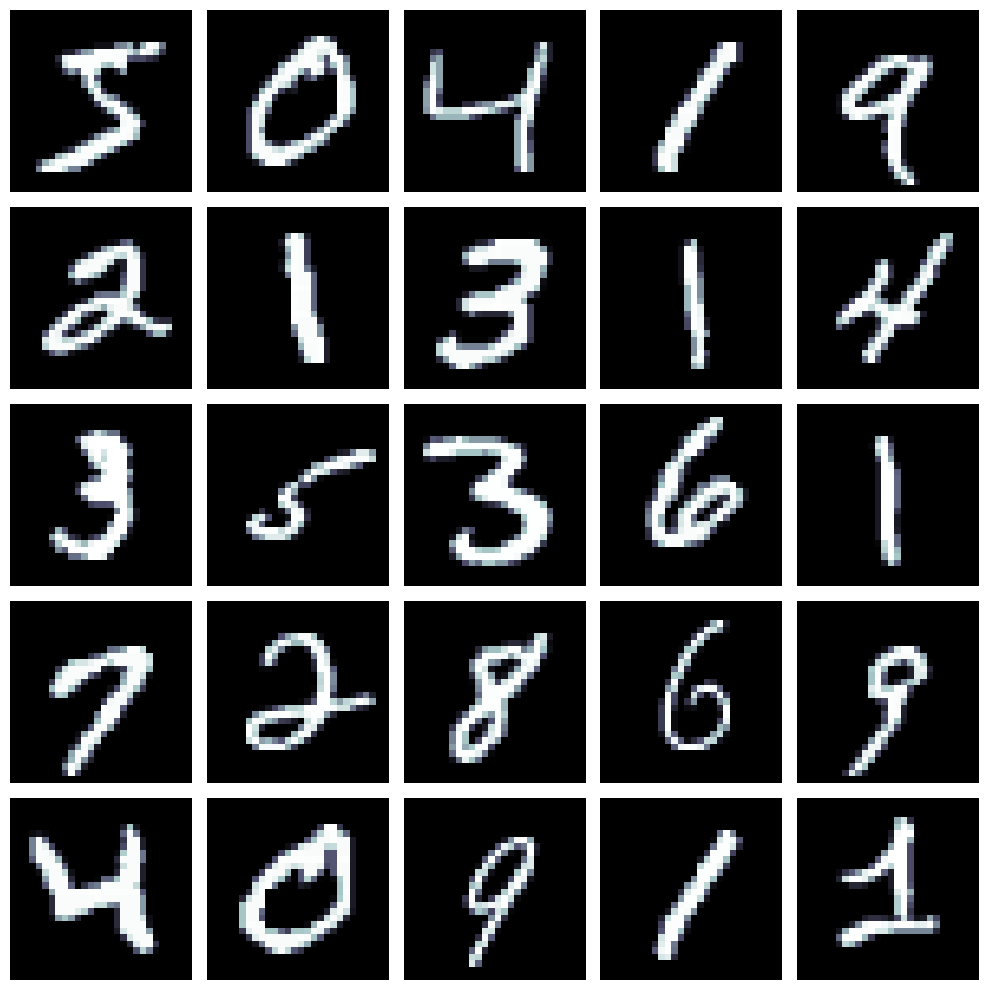

In [3]:
def plot_images(images, n_images=25):
    rows = int(np.sqrt(n_images))
    cols = int(np.sqrt(n_images))
    fig = plt.figure(figsize=(10, 10))
    for i in range(rows * cols):
        ax = fig.add_subplot(rows, cols, i+1)
        ax.imshow(images[i], cmap='bone')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

N_IMAGES = 25
images = [image for image, label in [train_data[i] for i in range(N_IMAGES)]]
plot_images(images)


### Preprocessing & Data Split


In [4]:
# Split train into train and validation (90:10)
VALID_RATIO = 0.9
n_train_examples = int(len(train_data) * VALID_RATIO)
n_valid_examples = len(train_data) - n_train_examples

train_data, valid_data = data.random_split(train_data, [n_train_examples, n_valid_examples])
print(f"Train: {len(train_data)}, Valid: {len(valid_data)}")


Train: 54000, Valid: 6000


In [5]:
# Compute mean and std for normalization
mean = train_data.dataset.data.float().mean() / 255
std = train_data.dataset.data.float().std() / 255

# Define transforms
train_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[mean], std=[std])
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[mean], std=[std])
])

train_data.dataset.transform = train_transforms
valid_data.dataset.transform = test_transforms
test_data.transform = test_transforms


### Create DataLoaders


In [6]:
BATCH_SIZE = 256

train_dataloader = data.DataLoader(train_data, shuffle=True, batch_size=BATCH_SIZE)
valid_dataloader = data.DataLoader(valid_data, batch_size=BATCH_SIZE)
test_dataloader = data.DataLoader(test_data, batch_size=BATCH_SIZE)

print(f"Number of batches - Train: {len(train_dataloader)}, Valid: {len(valid_dataloader)}, Test: {len(test_dataloader)}")


Number of batches - Train: 211, Valid: 24, Test: 40


### Define LeNet Model


In [22]:
class LeNetClassifier(nn.Module):
    def __init__(self, num_classes, in_channels=1, img_size=28):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=6,
                               kernel_size=5, padding='same')
        self.avgpool1 = nn.AvgPool2d(kernel_size=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, padding=0)
        self.avgpool2 = nn.AvgPool2d(kernel_size = 2)
        self.flatten = nn.Flatten()
        self.relu = nn.ReLU()

        # Calculate fc input size dynamically
        if img_size == 28:
            fc_input = 16 * 5 * 5
        else:  # for 150x150 images
            fc_input = 16 * 35 * 35

        self.fc_1 = nn.Linear(fc_input, 120)
        self.fc_2 = nn.Linear(120, 84)
        self.fc_3 = nn.Linear(84, num_classes)

    def forward(self, inputs):
        outputs = self.conv1(inputs)
        outputs = self.avgpool1(outputs)
        outputs = self.relu(outputs)

        outputs = self.conv2(outputs)
        outputs = self.avgpool2(outputs)
        outputs = self.relu(outputs)

        outputs = self.flatten(outputs)

        outputs = self.fc_1(outputs)
        outputs = self.relu(outputs)

        outputs = self.fc_2(outputs)
        outputs = self.relu(outputs)

        outputs = self.fc_3(outputs)
        return outputs


### Training & Evaluation Functions


In [23]:
def train(model, optimizer, criterion, train_dataloader, device, epoch=0, log_interval=50):
    model.train()
    total_acc, total_count = 0, 0
    losses = []
    start_time = time.time()

    for idx, (inputs, labels) in enumerate(train_dataloader):
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        predictions = model(inputs)

        loss = criterion(predictions, labels)
        losses.append(loss.item())

        loss.backward()
        optimizer.step()

        total_acc += (predictions.argmax(1) == labels).sum().item()
        total_count += labels.size(0)

        if idx % log_interval == 0 and idx > 0:
            print(f"| epoch {epoch:3d} | {idx:5d}/{len(train_dataloader):5d} batches | accuracy {total_acc / total_count:8.3f}")
            total_acc, total_count = 0, 0
            start_time = time.time()

    epoch_acc = total_acc / total_count if total_count > 0 else 0
    epoch_loss = sum(losses) / len(losses)
    return epoch_acc, epoch_loss


def evaluate(model, criterion, valid_dataloader, device):
    model.eval()
    total_acc, total_count = 0, 0
    losses = []

    with torch.no_grad():
        for idx, (inputs, labels) in enumerate(valid_dataloader):
            inputs = inputs.to(device)
            labels = labels.to(device)

            predictions = model(inputs)
            loss = criterion(predictions, labels)
            losses.append(loss.item())

            total_acc += (predictions.argmax(1) == labels).sum().item()
            total_count += labels.size(0)

    epoch_acc = total_acc / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_acc, epoch_loss


### Train MNIST Model


In [24]:
# Model setup
num_classes = len(train_data.dataset.classes)
lenet_model = LeNetClassifier(num_classes, in_channels=1, img_size=28).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(lenet_model.parameters())

# Training loop
num_epochs = 10
save_model = './model'
os.makedirs(save_model, exist_ok=True)

train_accs, train_losses = [], []
eval_accs, eval_losses = [], []
best_loss_eval = 100

for epoch in range(1, num_epochs + 1):
    epoch_start_time = time.time()

    # Training
    train_acc, train_loss = train(lenet_model, optimizer, criterion, train_dataloader, device, epoch)
    train_accs.append(train_acc)
    train_losses.append(train_loss)

    # Evaluation
    eval_acc, eval_loss = evaluate(lenet_model, criterion, valid_dataloader, device)
    eval_accs.append(eval_acc)
    eval_losses.append(eval_loss)

    # Save best model
    if eval_loss < best_loss_eval:
        best_loss_eval = eval_loss
        torch.save(lenet_model.state_dict(), os.path.join(save_model, 'lenet_mnist_model.pt'))

    # Print results
    print("-" * 80)
    print(f"| End of epoch {epoch:3d} | Time: {time.time() - epoch_start_time:5.2f}s | "
          f"Train Acc: {train_acc:8.3f} | Train Loss: {train_loss:8.3f} | "
          f"Valid Acc: {eval_acc:8.3f} | Valid Loss: {eval_loss:8.3f} |")
    print("-" * 80)

# Load best model
lenet_model.load_state_dict(torch.load(os.path.join(save_model, 'lenet_mnist_model.pt'), weights_only=True))
lenet_model.eval()


| epoch   1 |    50/  211 batches | accuracy    0.645
| epoch   1 |   100/  211 batches | accuracy    0.886
| epoch   1 |   150/  211 batches | accuracy    0.919
| epoch   1 |   200/  211 batches | accuracy    0.936
--------------------------------------------------------------------------------
| End of epoch   1 | Time: 14.04s | Train Acc:    0.954 | Train Loss:    0.517 | Valid Acc:    0.948 | Valid Loss:    0.174 |
--------------------------------------------------------------------------------
| epoch   2 |    50/  211 batches | accuracy    0.953
| epoch   2 |   100/  211 batches | accuracy    0.960
| epoch   2 |   150/  211 batches | accuracy    0.965
| epoch   2 |   200/  211 batches | accuracy    0.967
--------------------------------------------------------------------------------
| End of epoch   2 | Time: 13.36s | Train Acc:    0.967 | Train Loss:    0.127 | Valid Acc:    0.969 | Valid Loss:    0.109 |
-------------------------------------------------------------------------

LeNetClassifier(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=same)
  (avgpool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (avgpool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (relu): ReLU()
  (fc_1): Linear(in_features=400, out_features=120, bias=True)
  (fc_2): Linear(in_features=120, out_features=84, bias=True)
  (fc_3): Linear(in_features=84, out_features=10, bias=True)
)

### Plot Training Results


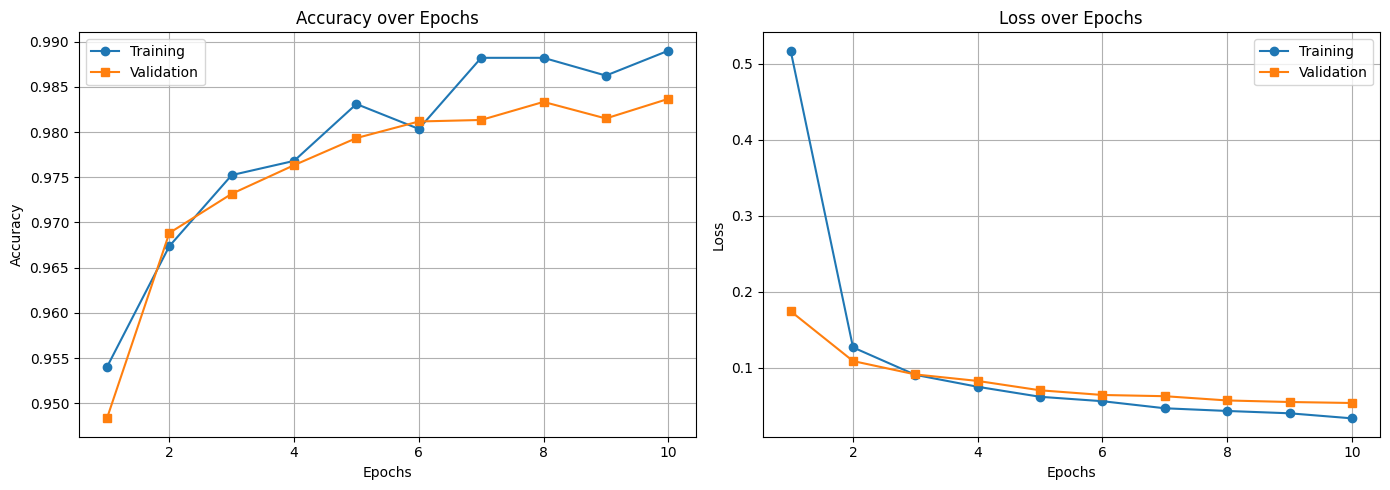

In [25]:
def plot_result(num_epochs, train_accs, eval_accs, train_losses, eval_losses):
    epochs = list(range(1, num_epochs + 1))
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

    axs[0].plot(epochs, train_accs, label="Training", marker='o')
    axs[0].plot(epochs, eval_accs, label="Validation", marker='s')
    axs[0].set_xlabel("Epochs")
    axs[0].set_ylabel("Accuracy")
    axs[0].set_title("Accuracy over Epochs")
    axs[0].legend()
    axs[0].grid(True)

    axs[1].plot(epochs, train_losses, label="Training", marker='o')
    axs[1].plot(epochs, eval_losses, label="Validation", marker='s')
    axs[1].set_xlabel("Epochs")
    axs[1].set_ylabel("Loss")
    axs[1].set_title("Loss over Epochs")
    axs[1].legend()
    axs[1].grid(True)

    plt.tight_layout()
    plt.show()

plot_result(num_epochs, train_accs, eval_accs, train_losses, eval_losses)


### Test on MNIST Test Set


In [26]:
test_acc, test_loss = evaluate(lenet_model, criterion, test_dataloader, device)
print(f"MNIST Test Accuracy: {test_acc:.4f}, Test Loss: {test_loss:.4f}")


MNIST Test Accuracy: 0.9852, Test Loss: 0.0449


### Visualize Learned Filters


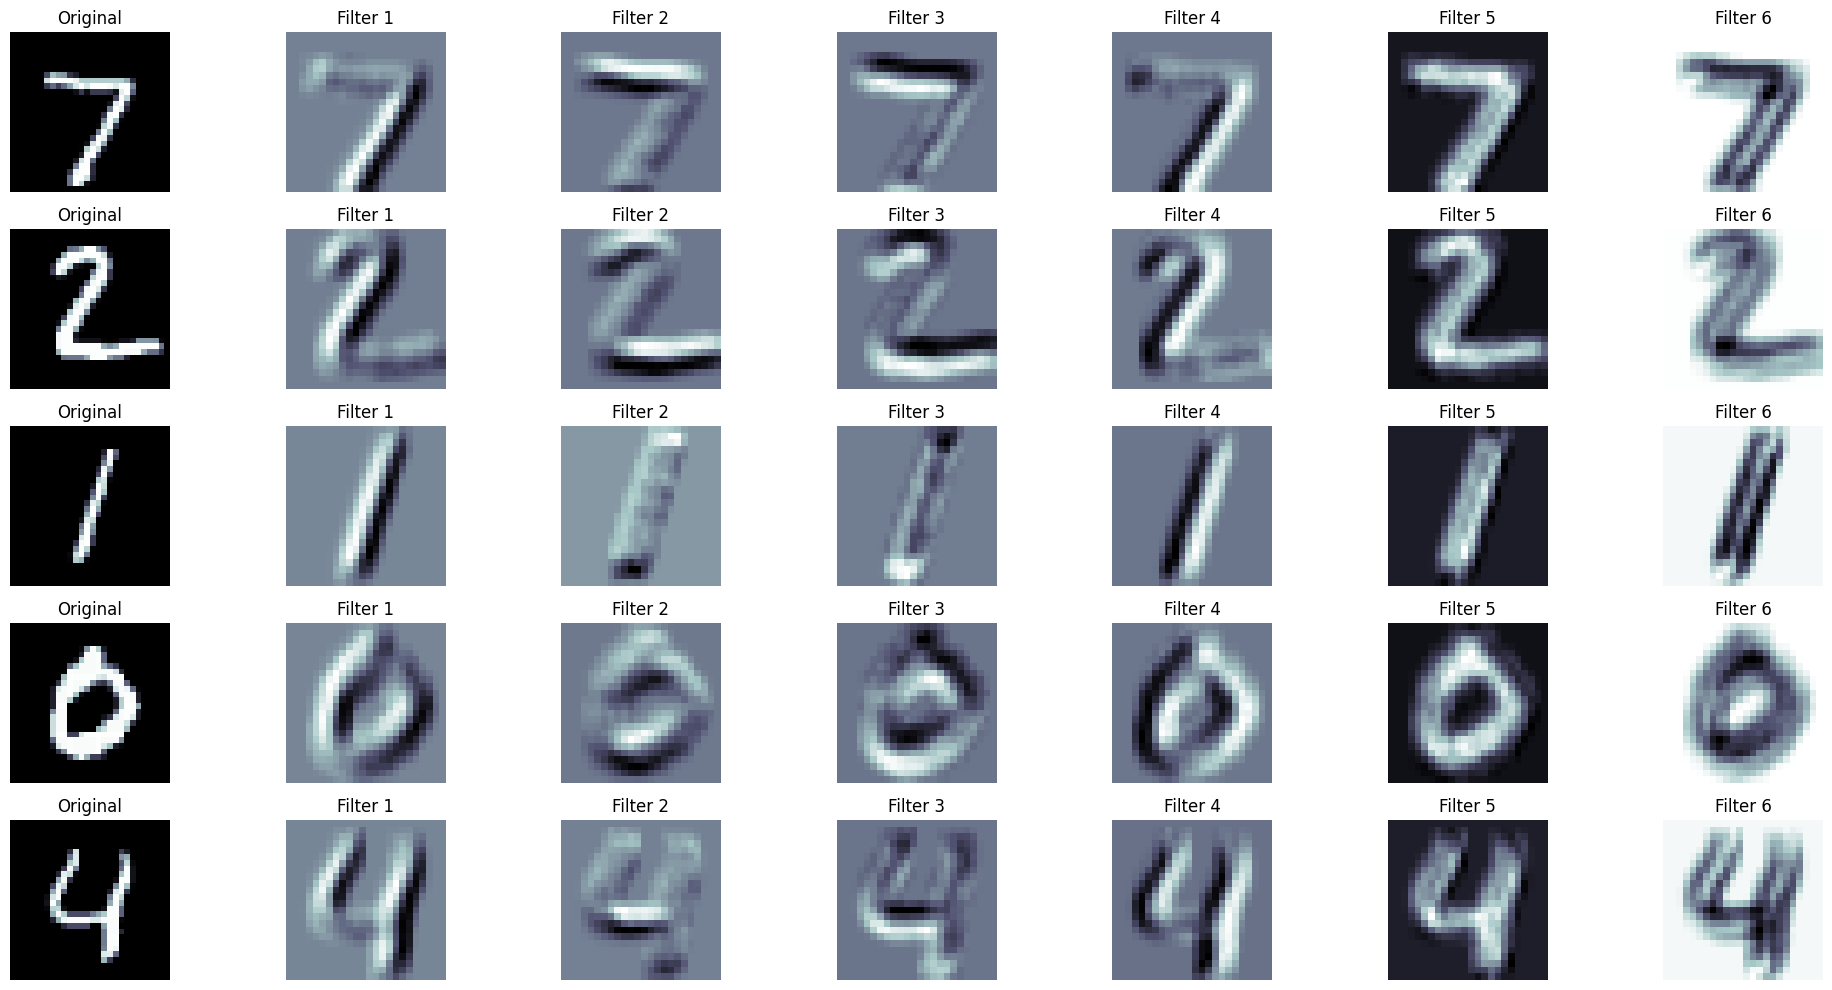

In [27]:
def plot_filtered_images(images, filters, n_images=5):
    images = torch.cat([i.unsqueeze(0) for i in images], dim=0).cpu()
    filters = filters.cpu()

    n_filters = filters.shape[0]
    filtered_images = F.conv2d(images, filters)

    fig = plt.figure(figsize=(20, 10))

    for i in range(n_images):
        ax = fig.add_subplot(n_images, n_filters + 1, i + 1 + (i * n_filters))
        ax.imshow(images[i].squeeze(0), cmap='bone')
        ax.set_title('Original')
        ax.axis('off')

        for j in range(n_filters):
            image = filtered_images[i][j]
            ax = fig.add_subplot(n_images, n_filters + 1, i + 1 + (i * n_filters) + j + 1)
            ax.imshow(image.numpy(), cmap='bone')
            ax.set_title(f'Filter {j + 1}')
            ax.axis('off')

    plt.tight_layout()
    plt.show()

N_IMAGES = 5
images = [image for image, label in [test_data[i] for i in range(N_IMAGES)]]
filters = lenet_model.conv1.weight.data
plot_filtered_images(images, filters)


### 🎯 Inference Function for MNIST


MNIST Inference Examples:


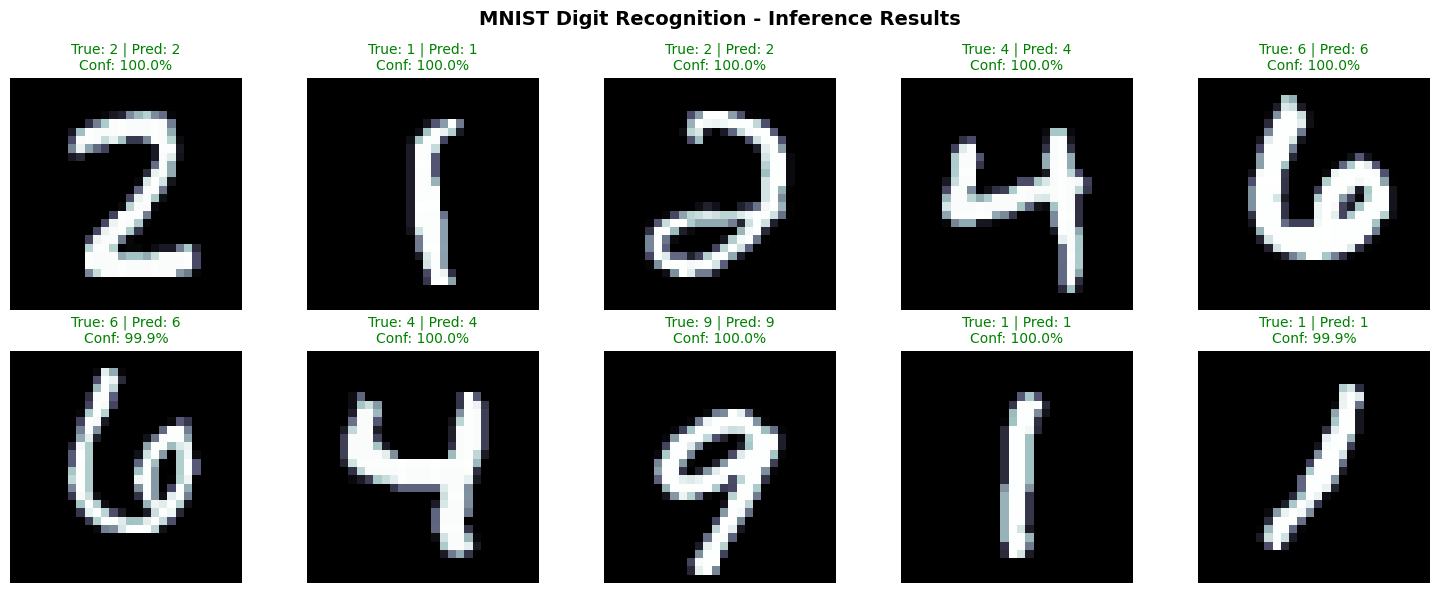

Inference completed for 10 random samples!
Green = Correct prediction, Red = Wrong prediction


In [28]:
def inference_mnist(image_tensor, model, device):
    """Predict digit from MNIST image tensor"""
    # Ensure image is in correct shape
    if image_tensor.dim() == 2:
        image_tensor = image_tensor.unsqueeze(0).unsqueeze(0)
    elif image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)

    model.eval()
    with torch.no_grad():
        predictions = model(image_tensor)

    probs = nn.Softmax(dim=1)(predictions)
    confidence, predicted_class = torch.max(probs, 1)

    return predicted_class.item(), confidence.item() * 100

# Test inference on random test images
print("MNIST Inference Examples:")
print("=" * 70)

n_samples = 10
random_indices = random.sample(range(len(test_data)), n_samples)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for idx, test_idx in enumerate(random_indices):
    image, true_label = test_data[test_idx]

    # Inference
    pred_class, confidence = inference_mnist(image, lenet_model, device)

    # Visualize
    axes[idx].imshow(image.squeeze().numpy(), cmap='bone')
    color = 'green' if pred_class == true_label else 'red'
    axes[idx].set_title(f'True: {true_label} | Pred: {pred_class}\nConf: {confidence:.1f}%',
                        color=color, fontsize=10)
    axes[idx].axis('off')

plt.suptitle('MNIST Digit Recognition - Inference Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Inference completed for {n_samples} random samples!")
print(f"Green = Correct prediction, Red = Wrong prediction")


---
## PART 1.2: Cassava Leaf Disease Classification
---


### Download Dataset (uncomment to download)


In [29]:
!wget --no-check-certificate https://storage.googleapis.com/emcassavadata/cassavaleafdata.zip -O ./cassavaleafdata.zip
!unzip ./cassavaleafdata.zip -d ./cassavaleafdata/


Streaming output truncated to the last 5000 lines.
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-679.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-68.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-680.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-681.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-682.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-683.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-684.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-685.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-686.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-687.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-688.jpg  
  inflating: ./cassavaleafdata/cassavaleafdata/train/cgm/train-cgm-689.jpg  
  inflating: ./cassavaleaf

### Setup Data Paths


In [30]:
data_paths = {
    'train': '../content/cassavaleafdata/cassavaleafdata/train',
    'valid': '../content/cassavaleafdata/cassavaleafdata/validation',
    'test': '../content/cassavaleafdata/cassavaleafdata/test'
}

labels_dict = {
    "cbb": "Cassava Bacterial Blight (CBB)",
    "cbsd": "Cassava Brown Streak Disease (CBSD)",
    "cgm": "Cassava Green Mottle (CGM)",
    "cmd": "Cassava Mosaic Disease (CMD)",
    "healthy": "Healthy"
}


### Preprocessing & DataLoader


In [31]:
img_size = 150

train_transforms_cassava = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
])

# Load datasets
cassava_train_data = datasets.ImageFolder(root=data_paths['train'], transform=train_transforms_cassava)
cassava_valid_data = datasets.ImageFolder(root=data_paths['valid'], transform=train_transforms_cassava)
cassava_test_data = datasets.ImageFolder(root=data_paths['test'], transform=train_transforms_cassava)

print(f"Cassava - Train: {len(cassava_train_data)}, Valid: {len(cassava_valid_data)}, Test: {len(cassava_test_data)}")


Cassava - Train: 5656, Valid: 1889, Test: 1885


In [32]:
BATCH_SIZE_CASSAVA = 256

cassava_train_dataloader = data.DataLoader(cassava_train_data, shuffle=True, batch_size=BATCH_SIZE_CASSAVA)
cassava_valid_dataloader = data.DataLoader(cassava_valid_data, batch_size=BATCH_SIZE_CASSAVA)
cassava_test_dataloader = data.DataLoader(cassava_test_data, batch_size=BATCH_SIZE_CASSAVA)


### Train Cassava Model


In [33]:
# Model setup
num_classes_cassava = len(cassava_train_data.classes)
cassava_model = LeNetClassifier(num_classes_cassava, in_channels=3, img_size=150).to(device)

criterion_cassava = nn.CrossEntropyLoss()
optimizer_cassava = optim.Adam(cassava_model.parameters(), lr=2e-4)

# Training loop
num_epochs = 10
save_model = './model'
os.makedirs(save_model, exist_ok=True)

train_accs, train_losses = [], []
eval_accs, eval_losses = [], []
best_loss_eval = 100

for epoch in range(1, num_epochs + 1):
    epoch_start_time = time.time()

    # Training
    train_acc, train_loss = train(cassava_model, optimizer_cassava, criterion_cassava,
                                   cassava_train_dataloader, device, epoch, log_interval=10)
    train_accs.append(train_acc)
    train_losses.append(train_loss)

    # Evaluation
    eval_acc, eval_loss = evaluate(cassava_model, criterion_cassava, cassava_valid_dataloader, device)
    eval_accs.append(eval_acc)
    eval_losses.append(eval_loss)

    # Save best model
    if eval_loss < best_loss_eval:
        best_loss_eval = eval_loss
        torch.save(cassava_model.state_dict(), os.path.join(save_model, 'lenet_cassava_model.pt'))

    # Print results
    print("-" * 80)
    print(f"| End of epoch {epoch:3d} | Time: {time.time() - epoch_start_time:5.2f}s | "
          f"Train Acc: {train_acc:8.3f} | Train Loss: {train_loss:8.3f} | "
          f"Valid Acc: {eval_acc:8.3f} | Valid Loss: {eval_loss:8.3f} |")
    print("-" * 80)

# Load best model
cassava_model.load_state_dict(torch.load(os.path.join(save_model, 'lenet_cassava_model.pt'), weights_only=True))
cassava_model.eval()


| epoch   1 |    10/   23 batches | accuracy    0.466
| epoch   1 |    20/   23 batches | accuracy    0.464
--------------------------------------------------------------------------------
| End of epoch   1 | Time: 46.28s | Train Acc:    0.475 | Train Loss:    1.398 | Valid Acc:    0.470 | Valid Loss:    1.454 |
--------------------------------------------------------------------------------
| epoch   2 |    10/   23 batches | accuracy    0.466
| epoch   2 |    20/   23 batches | accuracy    0.473
--------------------------------------------------------------------------------
| End of epoch   2 | Time: 45.99s | Train Acc:    0.479 | Train Loss:    1.347 | Valid Acc:    0.470 | Valid Loss:    1.454 |
--------------------------------------------------------------------------------
| epoch   3 |    10/   23 batches | accuracy    0.476
| epoch   3 |    20/   23 batches | accuracy    0.461
--------------------------------------------------------------------------------
| End of epoch   3 

LeNetClassifier(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1), padding=same)
  (avgpool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (avgpool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (relu): ReLU()
  (fc_1): Linear(in_features=19600, out_features=120, bias=True)
  (fc_2): Linear(in_features=120, out_features=84, bias=True)
  (fc_3): Linear(in_features=84, out_features=5, bias=True)
)

### 🎯 Inference Function for Cassava


Cassava Leaf Disease Inference Examples:


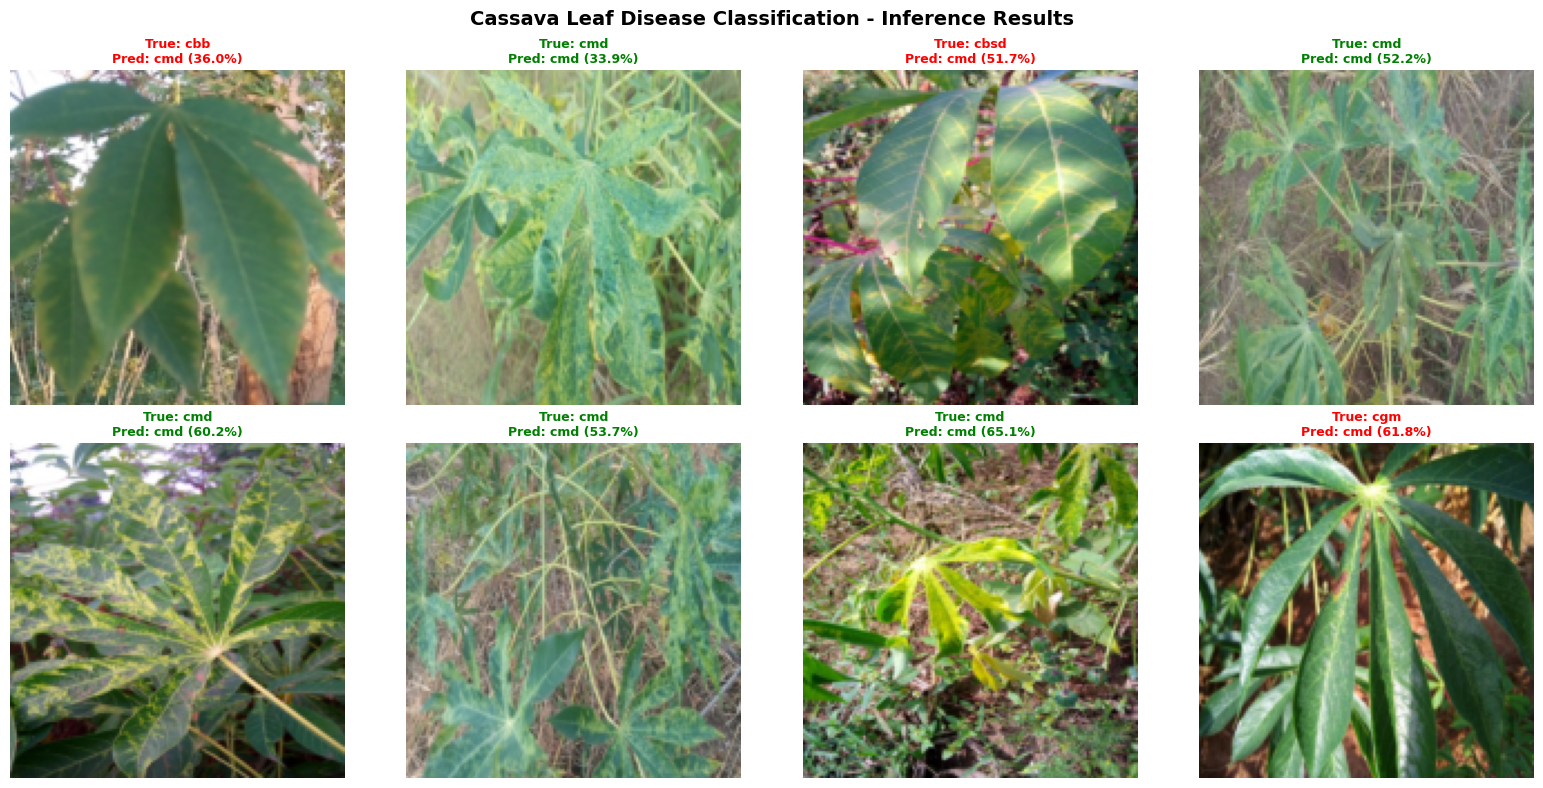

Inference completed for 8 random samples!
Green = Correct prediction, Red = Wrong prediction
Disease Labels:
  - cbb: Cassava Bacterial Blight (CBB)
  - cbsd: Cassava Brown Streak Disease (CBSD)
  - cgm: Cassava Green Mottle (CGM)
  - cmd: Cassava Mosaic Disease (CMD)
  - healthy: Healthy


In [37]:
def inference_cassava(image_path_or_tensor, model, transform, device, labels_dict):
    """Predict cassava disease from image"""
    # Load image if path is provided
    if isinstance(image_path_or_tensor, str):
        image = Image.open(image_path_or_tensor).convert('RGB')
        image_tensor = transform(image)
    else:
        image_tensor = image_path_or_tensor

    # Add batch dimension
    if image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)

    model.eval()
    with torch.no_grad():
        predictions = model(image_tensor)

    probs = nn.Softmax(dim=1)(predictions)
    confidence, predicted_class = torch.max(probs, 1)

    # Get class names
    idx_to_class = {v: k for k, v in cassava_train_data.class_to_idx.items()}
    predicted_label = idx_to_class[predicted_class.item()]
    disease_name = labels_dict[predicted_label]

    return predicted_label, disease_name, confidence.item() * 100

# Test inference on random test images
print("Cassava Leaf Disease Inference Examples:")
print("=" * 70)

n_samples = 8
random_indices = random.sample(range(len(cassava_test_data)), n_samples)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, test_idx in enumerate(random_indices):
    image_tensor, true_label_idx = cassava_test_data[test_idx]

    # Get true label name
    idx_to_class = {v: k for k, v in cassava_train_data.class_to_idx.items()}
    true_label = idx_to_class[true_label_idx]
    true_disease = labels_dict[true_label]

    # Inference
    pred_label, pred_disease, confidence = inference_cassava(
        image_tensor, cassava_model, train_transforms_cassava, device, labels_dict
    )

    # Visualize
    img_to_show = image_tensor.permute(1, 2, 0).numpy()
    axes[idx].imshow(img_to_show)
    color = 'green' if pred_label == true_label else 'red'
    axes[idx].set_title(f'True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)',
                        color=color, fontsize=9, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Cassava Leaf Disease Classification - Inference Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Inference completed for {n_samples} random samples!")
print(f"Green = Correct prediction, Red = Wrong prediction")
print(f"Disease Labels:")
for k, v in labels_dict.items():
    print(f"  - {k}: {v}")


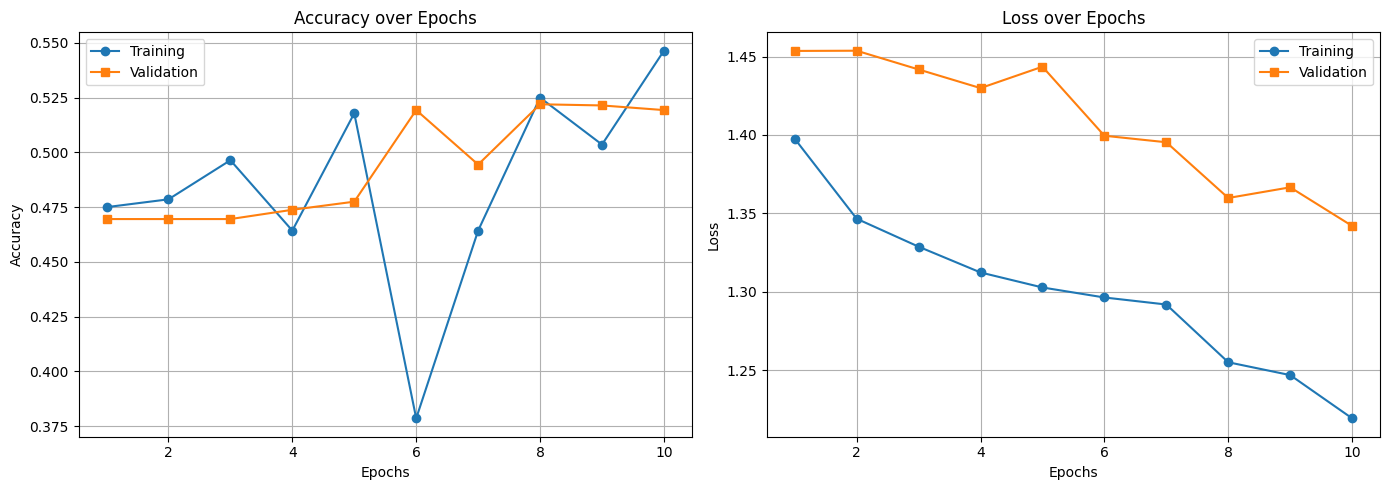

In [38]:
plot_result(num_epochs, train_accs, eval_accs, train_losses, eval_losses)


### Test on Cassava Test Set


In [39]:
test_acc, test_loss = evaluate(cassava_model, criterion_cassava, cassava_test_dataloader, device)
print(f"Cassava Test Accuracy: {test_acc:.4f}, Test Loss: {test_loss:.4f}")


Cassava Test Accuracy: 0.5204, Test Loss: 1.3332


---
---
# PROJECT 2: CNN FOR TEXT CLASSIFICATION
---
---


## Download Vietnamese Sentiment Dataset (uncomment to download)


In [40]:
!git clone https://github.com/congnghia0609/ntc-scv.git
!unzip ./ntc-scv/data/data_test.zip -d ./data
!unzip ./ntc-scv/data/data_train.zip -d ./data
!rm -rf ./ntc-scv


Streaming output truncated to the last 5000 lines.
  inflating: ./data/data_train/train/pos/31228.txt  
  inflating: ./data/data_train/train/pos/3123.txt  
  inflating: ./data/data_train/train/pos/31232.txt  
  inflating: ./data/data_train/train/pos/31233.txt  
  inflating: ./data/data_train/train/pos/31234.txt  
  inflating: ./data/data_train/train/pos/31236.txt  
  inflating: ./data/data_train/train/pos/31238.txt  
  inflating: ./data/data_train/train/pos/31240.txt  
  inflating: ./data/data_train/train/pos/31242.txt  
  inflating: ./data/data_train/train/pos/31247.txt  
  inflating: ./data/data_train/train/pos/31250.txt  
  inflating: ./data/data_train/train/pos/31251.txt  
  inflating: ./data/data_train/train/pos/31252.txt  
  inflating: ./data/data_train/train/pos/31257.txt  
  inflating: ./data/data_train/train/pos/31260.txt  
  inflating: ./data/data_train/train/pos/31261.txt  
  inflating: ./data/data_train/train/pos/31262.txt  
  inflating: ./data/data_train/train/pos/31273.tx

## Load & Preprocess Text Data


In [41]:
import pandas as pd

def load_data_from_path(folder_path):
    examples = []
    for label in os.listdir(folder_path):
        full_path = os.path.join(folder_path, label)
        for file_name in os.listdir(full_path):
            file_path = os.path.join(full_path, file_name)
            with open(file_path, "r", encoding="utf-8") as f:
                lines = f.readlines()
            sentence = " ".join(lines)
            label_id = 0 if label == "neg" else 1
            examples.append({'sentence': sentence, 'label': label_id})
    return pd.DataFrame(examples)

folder_paths_text = {
    'train': './data/data_train/train',
    'valid': './data/data_train/test',
    'test': './data/data_test/test'
}

train_df = load_data_from_path(folder_paths_text['train'])
valid_df = load_data_from_path(folder_paths_text['valid'])
test_df = load_data_from_path(folder_paths_text['test'])

print(f"Train: {len(train_df)}, Valid: {len(valid_df)}, Test: {len(test_df)}")


Train: 30000, Valid: 10000, Test: 10000


### Text Preprocessing


In [42]:
import re
import string

def preprocess_text(text):
    # Remove URLs
    url_pattern = re.compile(r'https?://\S+|www\.\S+')
    text = url_pattern.sub(r" ", text)

    # Remove HTML Tags
    html_pattern = re.compile(r'<[^<>]+>')
    text = html_pattern.sub(" ", text)

    # Remove punctuation and digits
    replace_chars = list(string.punctuation + string.digits)
    for char in replace_chars:
        text = text.replace(char, " ")

    # Remove emoji
    emoji_pattern = re.compile("["
        u"\U0001F600-\U0001F64F"
        u"\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF"
        u"\U0001F1E0-\U0001F1FF"
        u"\U0001F1F2-\U0001F1F4"
        u"\U0001F1E6-\U0001F1FF"
        u"\U0001F600-\U0001F64F"
        u"\U00002702-\U000027B0"
        u"\U000024C2-\U0001F251"
        u"\U0001f926-\U0001f937"
        u"\U0001F1F2"
        u"\U0001F1F4"
        u"\U0001F620"
        u"\u200d"
        u"\u2640-\u2642"
        "]+", flags=re.UNICODE)
    text = emoji_pattern.sub(r" ", text)

    # Normalize whitespace and lowercase
    text = " ".join(text.split()).lower()
    return text

# Apply preprocessing
train_df['preprocess_sentence'] = train_df['sentence'].apply(preprocess_text)
valid_df['preprocess_sentence'] = valid_df['sentence'].apply(preprocess_text)
test_df['preprocess_sentence'] = test_df['sentence'].apply(preprocess_text)


## Build Vocabulary


In [43]:
from collections import Counter

# Simple tokenizer: split by space
def simple_tokenizer(text):
    return text.split()

# Build vocabulary
def build_vocab(texts, max_vocab_size=10000):
    word_freq = Counter()
    for text in texts:
        tokens = simple_tokenizer(text)
        word_freq.update(tokens)

    # Get most common words
    most_common = word_freq.most_common(max_vocab_size - 2)  # -2 for <pad> and <unk>

    # Create word to index mapping
    word2idx = {"<pad>": 0, "<unk>": 1}
    for idx, (word, freq) in enumerate(most_common, start=2):
        word2idx[word] = idx

    return word2idx

# Encode function
def encode_text(text, word2idx):
    tokens = simple_tokenizer(text)
    return [word2idx.get(token, word2idx["<unk>"]) for token in tokens]

# Build vocabulary from training data
word2idx = build_vocab(train_df['preprocess_sentence'], max_vocab_size=10000)
vocab_size = len(word2idx)

print(f"Vocabulary size: {vocab_size}")
print(f"Sample words: {list(word2idx.items())[:10]}")


Vocabulary size: 10000
Sample words: [('<pad>', 0), ('<unk>', 1), ('ăn', 2), ('mình', 3), ('có', 4), ('là', 5), ('không', 6), ('quán', 7), ('thì', 8), ('và', 9)]


## Create Dataset & DataLoader


In [44]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

# Custom Dataset
class TextDataset(Dataset):
    def __init__(self, df, word2idx):
        self.texts = df['preprocess_sentence'].values
        self.labels = df['label'].values
        self.word2idx = word2idx

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = encode_text(self.texts[idx], self.word2idx)
        return torch.tensor(encoded, dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.long)

# Collate function for batching
def collate_batch(batch):
    encoded_sentences, labels = [], []
    for encoded, label in batch:
        encoded_sentences.append(encoded)
        labels.append(label)

    # Pad sequences
    encoded_sentences = pad_sequence(encoded_sentences, padding_value=word2idx["<pad>"])
    labels = torch.tensor(labels, dtype=torch.long)

    return encoded_sentences, labels

# Create datasets
text_train_dataset = TextDataset(train_df, word2idx)
text_valid_dataset = TextDataset(valid_df, word2idx)
text_test_dataset = TextDataset(test_df, word2idx)

# Create dataloaders
batch_size = 128
text_train_dataloader = DataLoader(text_train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_batch)
text_valid_dataloader = DataLoader(text_valid_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_batch)
text_test_dataloader = DataLoader(text_test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_batch)

print(f"Train dataset: {len(text_train_dataset)}, Valid dataset: {len(text_valid_dataset)}, Test dataset: {len(text_test_dataset)}")
print(f"Number of batches - Train: {len(text_train_dataloader)}, Valid: {len(text_valid_dataloader)}, Test: {len(text_test_dataloader)}")


Train dataset: 30000, Valid dataset: 10000, Test dataset: 10000
Number of batches - Train: 235, Valid: 79, Test: 79


## Define TextCNN Model


In [49]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, kernel_sizes, num_filters, num_classes):
        super(TextCNN, self).__init__()

        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.kernel_sizes = kernel_sizes
        self.num_filters = num_filters
        self.num_classes = num_classes

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.conv = nn.ModuleList([
            nn.Conv1d(in_channels=embedding_dim, out_channels=num_filters, kernel_size=k, stride=1)
            for k in kernel_sizes
        ])
        self.fc = nn.Linear(len(kernel_sizes) * num_filters, num_classes)

    def forward(self, x):
        # x shape: (seq_len, batch_size)
        x = self.embedding(x).permute(1, 2, 0)  # (batch_size, embedding_dim, seq_len)
        x = [F.relu(conv(x)) for conv in self.conv]
        x = [F.max_pool1d(c, c.size(-1)).squeeze(dim=-1) for c in x]
        x = torch.cat(x, dim=1)
        x = self.fc(x)
        return x


## Train TextCNN Model


In [50]:
# Model setup (vocab_size đã được tạo ở cell 48)
embedding_dim = 100

text_model = TextCNN(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    kernel_sizes=[3, 4, 5],
    num_filters=100,
    num_classes=2
).to(device)

print(f"Text Model initialized on {device}")
print(f"Vocab size: {vocab_size}, Embedding dim: {embedding_dim}")
print(f"Total parameters: {sum(p.numel() for p in text_model.parameters()):,}")

criterion_text = nn.CrossEntropyLoss()
optimizer_text = optim.Adam(text_model.parameters())

# Training loop
num_epochs = 4
save_model = './model'
os.makedirs(save_model, exist_ok=True)

train_accs, train_losses = [], []
eval_accs, eval_losses = [], []
best_loss_eval = 100

for epoch in range(1, num_epochs + 1):
    epoch_start_time = time.time()

    # Training
    train_acc, train_loss = train(text_model, optimizer_text, criterion_text,
                                   text_train_dataloader, device, epoch, log_interval=50)
    train_accs.append(train_acc)
    train_losses.append(train_loss)

    # Evaluation
    eval_acc, eval_loss = evaluate(text_model, criterion_text, text_valid_dataloader, device)
    eval_accs.append(eval_acc)
    eval_losses.append(eval_loss)

    # Save best model
    if eval_loss < best_loss_eval:
        best_loss_eval = eval_loss
        torch.save(text_model.state_dict(), os.path.join(save_model, 'text_cnn_model.pt'))

    # Print results
    print("-" * 80)
    print(f"| End of epoch {epoch:3d} | Time: {time.time() - epoch_start_time:5.2f}s | "
          f"Train Acc: {train_acc:8.3f} | Train Loss: {train_loss:8.3f} | "
          f"Valid Acc: {eval_acc:8.3f} | Valid Loss: {eval_loss:8.3f} |")
    print("-" * 80)

# Load best model
text_model.load_state_dict(torch.load(os.path.join(save_model, 'text_cnn_model.pt'), weights_only=True))
text_model.eval()


Text Model initialized on cuda
Vocab size: 10000, Embedding dim: 100
Total parameters: 1,120,902
| epoch   1 |    50/  235 batches | accuracy    0.736
| epoch   1 |   100/  235 batches | accuracy    0.833
| epoch   1 |   150/  235 batches | accuracy    0.861
| epoch   1 |   200/  235 batches | accuracy    0.863
--------------------------------------------------------------------------------
| End of epoch   1 | Time: 11.48s | Train Acc:    0.871 | Train Loss:    0.386 | Valid Acc:    0.868 | Valid Loss:    0.315 |
--------------------------------------------------------------------------------
| epoch   2 |    50/  235 batches | accuracy    0.910
| epoch   2 |   100/  235 batches | accuracy    0.909
| epoch   2 |   150/  235 batches | accuracy    0.917
| epoch   2 |   200/  235 batches | accuracy    0.917
--------------------------------------------------------------------------------
| End of epoch   2 | Time: 11.58s | Train Acc:    0.923 | Train Loss:    0.234 | Valid Acc:    0.882 |

TextCNN(
  (embedding): Embedding(10000, 100, padding_idx=0)
  (conv): ModuleList(
    (0): Conv1d(100, 100, kernel_size=(3,), stride=(1,))
    (1): Conv1d(100, 100, kernel_size=(4,), stride=(1,))
    (2): Conv1d(100, 100, kernel_size=(5,), stride=(1,))
  )
  (fc): Linear(in_features=300, out_features=2, bias=True)
)

## Plot Training Results


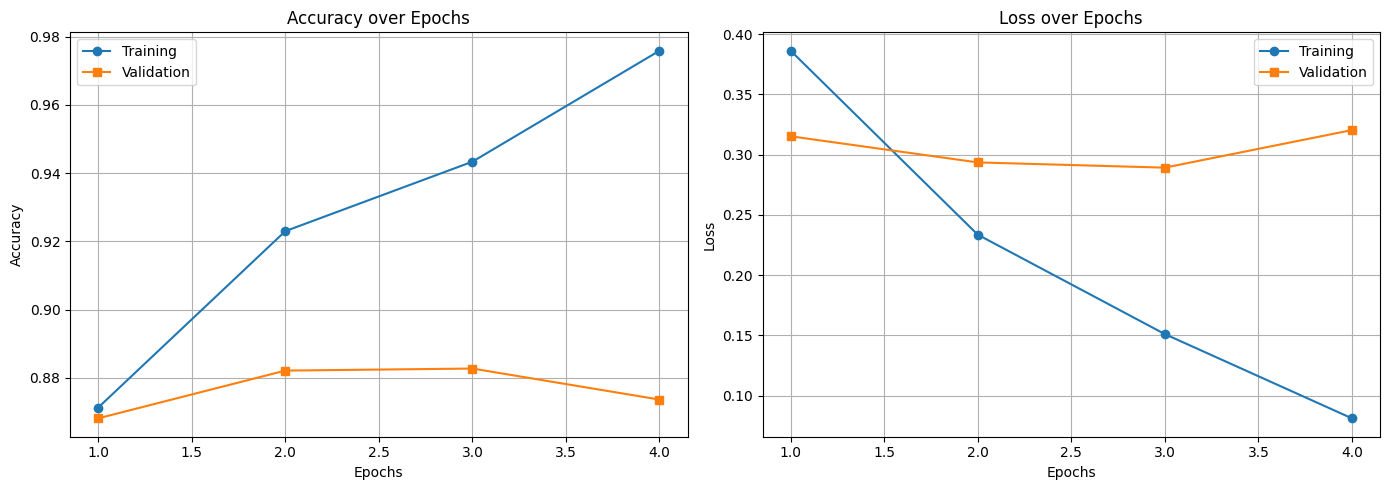

In [51]:
plot_result(num_epochs, train_accs, eval_accs, train_losses, eval_losses)


## Test on Text Test Set


In [52]:
test_acc, test_loss = evaluate(text_model, criterion_text, text_test_dataloader, device)
print(f"Text Classification Test Accuracy: {test_acc:.4f}, Test Loss: {test_loss:.4f}")


Text Classification Test Accuracy: 0.8877, Test Loss: 0.2785


## Inference Function for Text Classification


In [53]:
def inference_text(sentence, word2idx, model, device):
    """Predict sentiment of a given sentence"""
    preprocessed = preprocess_text(sentence)
    encoded_sentence = encode_text(preprocessed, word2idx)
    encoded_sentence = torch.tensor(encoded_sentence, dtype=torch.long)
    encoded_sentence = torch.unsqueeze(encoded_sentence, 1).to(device)

    model.eval()
    with torch.no_grad():
        predictions = model(encoded_sentence)
    preds = nn.Softmax(dim=1)(predictions)
    p_max, yhat = torch.max(preds.data, 1)

    sentiment = "Positive" if yhat.item() == 1 else "Negative"
    confidence = round(p_max.item() * 100, 2)

    return sentiment, confidence

# Test inference
test_sentences = [
    # Positive
    "Sản phẩm rất tốt, tôi rất hài lòng!",
    "Giao hàng nhanh, đóng gói cẩn thận.",

    # Negative
    "Chất lượng tệ, không đáng tiền.",
    "Sản phẩm bị hỏng, dịch vụ hỗ trợ rất chậm.",
    "Màu sắc khác hoàn toàn so với hình, tôi rất thất vọng."
]


for sentence in test_sentences:
    sentiment, confidence = inference_text(sentence, word2idx, text_model, device)
    print(f"Sentence: {sentence}")
    print(f"Sentiment: {sentiment}, Confidence: {confidence}%")
    print("-" * 50)


Sentence: Sản phẩm rất tốt, tôi rất hài lòng!
Sentiment: Positive, Confidence: 98.85%
--------------------------------------------------
Sentence: Giao hàng nhanh, đóng gói cẩn thận.
Sentiment: Positive, Confidence: 99.58%
--------------------------------------------------
Sentence: Chất lượng tệ, không đáng tiền.
Sentiment: Negative, Confidence: 99.97%
--------------------------------------------------
Sentence: Sản phẩm bị hỏng, dịch vụ hỗ trợ rất chậm.
Sentiment: Positive, Confidence: 60.59%
--------------------------------------------------
Sentence: Màu sắc khác hoàn toàn so với hình, tôi rất thất vọng.
Sentiment: Positive, Confidence: 64.44%
--------------------------------------------------


---
## Summary

Notebook này đã hoàn thành 2 projects:

### Project 1: CNN for Image Classification
- **MNIST**: Phân loại chữ số viết tay (0-9) với LeNet architecture
- **Cassava Leaf Disease**: Phân loại 5 loại bệnh lá sắn

### Project 2: CNN for Text Classification  
- Phân loại sentiment (Positive/Negative) cho văn bản tiếng Việt sử dụng TextCNN
